# CC2017 – Deep Learning · Proyecto Final
## 03 · Transfer learning y fine-tuning con MobileNetV2

MobileNetV2 fue preentrenado en ImageNet (1.2 millones de imágenes, 1,000 clases). Se reemplaza su clasificador por uno de 43 clases y se adapta en dos etapas:
- **Etapa A · extracción de características:** el backbone queda congelado y solo se entrena el clasificador nuevo.
- **Etapa B · fine-tuning:** se descongelan los últimos bloques y se entrenan con una tasa de aprendizaje 10 veces menor, para ajustar las características sin destruir lo aprendido.

## Preparación · Librerías, reproducibilidad y dispositivo

In [1]:
import sys, random, time
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import torch
from torch import nn
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
device = torch.device('cuda' if torch.cuda.is_available() else 'mps' if torch.backends.mps.is_available() else 'cpu')
OUT = ROOT / 'outputs'; OUT.mkdir(exist_ok=True)

# FAST_DEV_RUN=True recorre pocos lotes por época para comprobar que todo corre; sus checkpoints llevan prefijo dev_.
FAST_DEV_RUN = False
MAX_BATCHES = 5 if FAST_DEV_RUN else None
PREFIX = 'dev_' if FAST_DEV_RUN else ''
NUM_WORKERS = 2
print('Dispositivo:', device, '| FAST_DEV_RUN:', FAST_DEV_RUN)

Dispositivo: cpu | FAST_DEV_RUN: False


## 1. Datos
Se usa 96×96 en lugar de 224×224 para que el entrenamiento sea viable en CPU. Las imágenes se normalizan con la media y desviación de ImageNet, que es lo que espera el backbone.

In [2]:
from src.data import download_gtsrb, load_tables, split_train_val, GTSRBDataset, get_transforms, CLASS_NAMES, NUM_CLASSES

DATA_ROOT = download_gtsrb()
train_full, test_df = load_tables(DATA_ROOT)
train_df, val_df = split_train_val(train_full, val_size=0.15, seed=SEED)
print(f'Train: {len(train_df):,} | Val: {len(val_df):,} | Test: {len(test_df):,}')

c:\Users\mdax8\Desktop\UVG\8 Semestre\Deep Learning\Proyecto Final\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Train: 33,299 | Val: 5,910 | Test: 12,630


In [3]:
IMG_SIZE = 96
batch_size = 64

train_ds = GTSRBDataset(train_df, DATA_ROOT, get_transforms(IMG_SIZE, augment=True, imagenet_norm=True))
val_ds = GTSRBDataset(val_df, DATA_ROOT, get_transforms(IMG_SIZE, imagenet_norm=True))
train_loader = DataLoader(train_ds, batch_size, shuffle=True, num_workers=NUM_WORKERS, persistent_workers=NUM_WORKERS > 0)
val_loader = DataLoader(val_ds, batch_size, num_workers=NUM_WORKERS, persistent_workers=NUM_WORKERS > 0)

## 2. Etapa A · Backbone congelado

In [4]:
from src.models import build_mobilenet_v2, unfreeze_last_blocks, count_params
from src.train import fit

mnet = build_mobilenet_v2(freeze_backbone=True).to(device)
total, trainable_a = count_params(mnet)
print(f'Parámetros: {total:,} | entrenables en etapa A: {trainable_a:,} ({trainable_a/total:.1%})')

opt_a = torch.optim.Adam([p for p in mnet.parameters() if p.requires_grad], lr=1e-3)
sched_a = torch.optim.lr_scheduler.ReduceLROnPlateau(opt_a, factor=0.5, patience=2)
hist_a = fit(mnet, train_loader, val_loader, opt_a, device, epochs=2 if FAST_DEV_RUN else 10,
             scheduler=sched_a, patience=3, ckpt_path=OUT / f'{PREFIX}mobilenet_frozen.pt', max_batches=MAX_BATCHES)

Downloading: "https://download.pytorch.org/models/mobilenet_v2-b0353104.pth" to C:\Users\mdax8/.cache\torch\hub\checkpoints\mobilenet_v2-b0353104.pth


100%|██████████| 13.6M/13.6M [00:00<00:00, 17.7MB/s]


Parámetros: 2,278,955 | entrenables en etapa A: 55,083 (2.4%)
Época 01 | train loss 1.4754 acc 0.5624 | val loss 1.6189 acc 0.5103 | lr 1.0e-03 | 124s
Época 02 | train loss 1.1085 acc 0.6474 | val loss 1.5797 acc 0.5239 | lr 1.0e-03 | 100s
Época 03 | train loss 1.0315 acc 0.6714 | val loss 1.4932 acc 0.5552 | lr 1.0e-03 | 103s
Época 04 | train loss 0.9958 acc 0.6766 | val loss 1.5225 acc 0.5538 | lr 1.0e-03 | 101s
Época 05 | train loss 0.9849 acc 0.6807 | val loss 1.5234 acc 0.5450 | lr 1.0e-03 | 95s
Época 06 | train loss 0.9724 acc 0.6855 | val loss 1.4680 acc 0.5635 | lr 1.0e-03 | 97s
Época 07 | train loss 0.9566 acc 0.6909 | val loss 1.5304 acc 0.5555 | lr 1.0e-03 | 85s
Época 08 | train loss 0.9514 acc 0.6922 | val loss 1.5311 acc 0.5662 | lr 1.0e-03 | 90s
Época 09 | train loss 0.9472 acc 0.6905 | val loss 1.5185 acc 0.5548 | lr 1.0e-03 | 89s
Early stopping en la época 9


## 3. Etapa B · Fine-tuning
Se parte de los pesos de la etapa A y se descongelan los últimos 4 bloques de `features`. Se usan dos grupos de parámetros: lr 1e-4 para el backbone y 1e-3 para el clasificador. Para el avance esta etapa es opcional: con `RUN_FINETUNE = False` se omite.

In [5]:
RUN_FINETUNE = True

if RUN_FINETUNE:
    mnet_ft = build_mobilenet_v2(freeze_backbone=True).to(device)
    mnet_ft.load_state_dict(mnet.state_dict())
    unfreeze_last_blocks(mnet_ft, n_blocks=4)
    _, trainable_b = count_params(mnet_ft)
    print(f'Entrenables en etapa B: {trainable_b:,} ({trainable_b/total:.1%})')
    backbone = [p for p in mnet_ft.features.parameters() if p.requires_grad]
    opt_b = torch.optim.Adam([{'params': backbone, 'lr': 1e-4},
                              {'params': mnet_ft.classifier.parameters(), 'lr': 1e-3}])
    sched_b = torch.optim.lr_scheduler.ReduceLROnPlateau(opt_b, factor=0.5, patience=2)
    hist_b = fit(mnet_ft, train_loader, val_loader, opt_b, device, epochs=2 if FAST_DEV_RUN else 10,
                 scheduler=sched_b, patience=3, ckpt_path=OUT / f'{PREFIX}mobilenet_finetuned.pt', max_batches=MAX_BATCHES)

Entrenables en etapa B: 1,581,163 (69.4%)
Época 01 | train loss 0.7170 acc 0.7595 | val loss 1.2272 acc 0.6609 | lr 1.0e-04 | 115s
Época 02 | train loss 0.4665 acc 0.8403 | val loss 1.0224 acc 0.7019 | lr 1.0e-04 | 119s
Época 03 | train loss 0.3579 acc 0.8787 | val loss 1.1068 acc 0.7139 | lr 1.0e-04 | 129s
Época 04 | train loss 0.3008 acc 0.8977 | val loss 1.0952 acc 0.7105 | lr 1.0e-04 | 135s
Época 05 | train loss 0.2579 acc 0.9121 | val loss 1.0067 acc 0.7501 | lr 1.0e-04 | 133s
Época 06 | train loss 0.2342 acc 0.9200 | val loss 1.1249 acc 0.7409 | lr 1.0e-04 | 132s
Época 07 | train loss 0.2126 acc 0.9279 | val loss 1.0595 acc 0.7382 | lr 1.0e-04 | 113s
Época 08 | train loss 0.1909 acc 0.9351 | val loss 1.0733 acc 0.7443 | lr 1.0e-04 | 114s
Early stopping en la época 8


## 4. Comparación de etapas

,modelo,accuracy,precision_macro,recall_macro,f1_macro,precision_weighted,recall_weighted,f1_weighted,params_entrenables,épocas,s_por_época
0,MobileNetV2 congelado,0.5635,0.5047,0.4522,0.4558,0.5746,0.5635,0.5519,55083,9,98.1806
1,MobileNetV2 fine-tuning,0.7501,0.6996,0.6450,0.6521,0.7616,0.7501,0.7427,1581163,8,123.7480


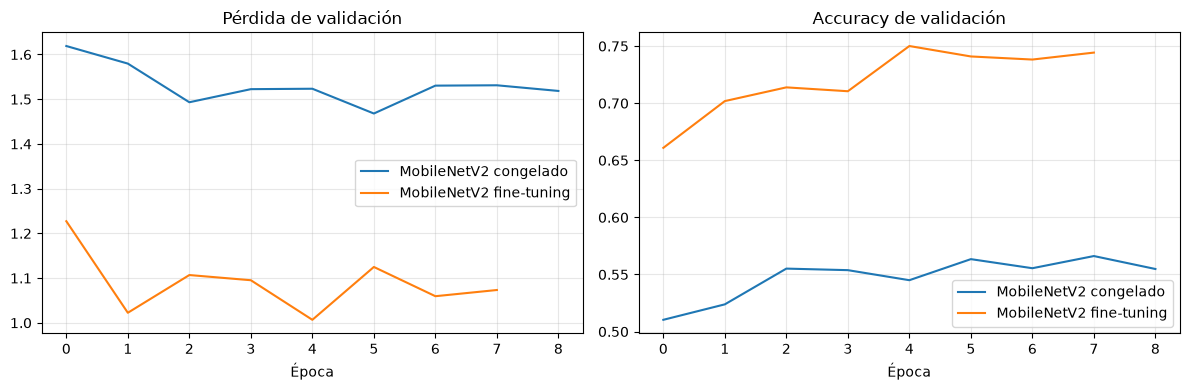

In [6]:
from src.metrics import predict, summary_metrics
stages = [('MobileNetV2 congelado', mnet, hist_a, trainable_a)]
if RUN_FINETUNE: stages.append(('MobileNetV2 fine-tuning', mnet_ft, hist_b, trainable_b))
rows = []
for name, model, h, n_train in stages:
    y, p, _ = predict(model, val_loader, device, MAX_BATCHES)
    rows.append({**summary_metrics(y, p, name), 'params_entrenables': n_train,
                 'épocas': len(h['val_loss']), 's_por_época': np.mean(h['epoch_time'])})
display(pd.DataFrame(rows).round(4))

fig, axs = plt.subplots(1, 2, figsize=(12, 4))
for name, _, h, _ in stages:
    axs[0].plot(h['val_loss'], label=name); axs[1].plot(h['val_acc'], label=name)
axs[0].set(title='Pérdida de validación', xlabel='Época'); axs[1].set(title='Accuracy de validación', xlabel='Época')
for ax in axs: ax.legend(); ax.grid(alpha=.3)
plt.tight_layout(); plt.savefig(OUT / 'curvas_mobilenet.png', dpi=120); plt.show()

**Interpretación.** Con el backbone congelado solo se entrenó el 2.4% de los parámetros y se obtuvo 0.5635 de accuracy y 0.4558 de F1 macro en validación. Al descongelar los últimos cuatro bloques, el porcentaje entrenable aumentó a 69.4% y la accuracy subió a 0.7501, mientras que el F1 macro llegó a 0.6521. El costo medio aumentó de 98.2 a 123.7 segundos por época. La mejora confirma que las características de ImageNet no se transfieren directamente al dominio de señales pequeñas y que el ajuste del backbone es necesario.